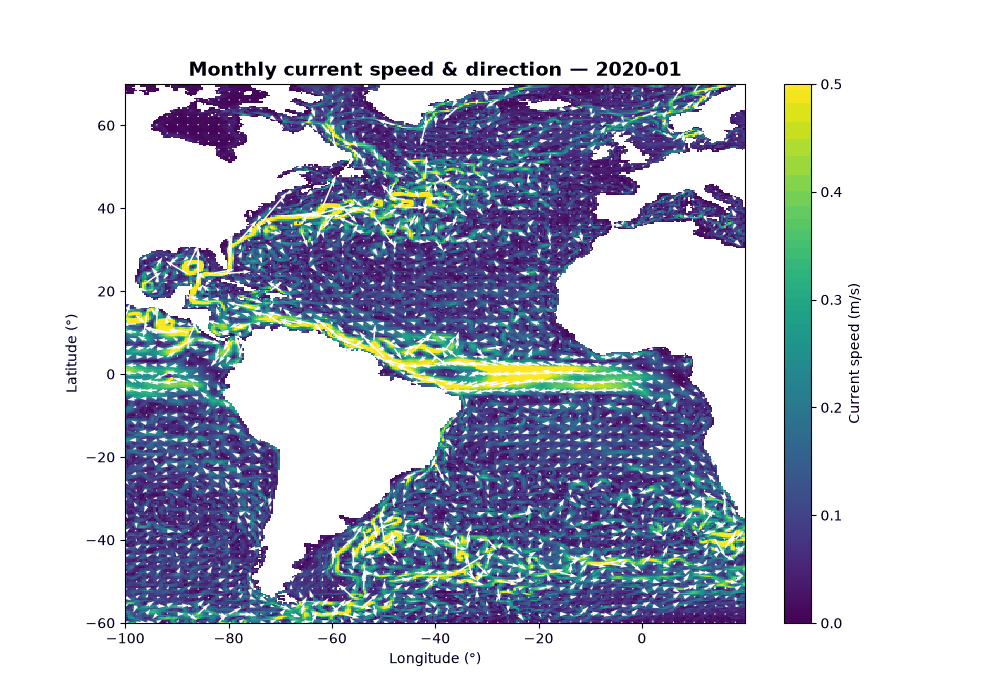

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

# --- 1. Load and filter data (2020-2022, Atlantic surface) ---
data = xr.open_mfdataset("../data/currents-20*.nc", combine="by_coords")
data = (
    data.sel(time=slice("2020-01-01", "2022-12-31"),
             longitude=slice(-100, 20),
             latitude=slice(-60, 70))
        .isel(depth=0, drop=True)
        .coarsen(longitude=4, latitude=4, boundary="trim").mean()
        .load()
)

# --- 2. Compute speed and month labels ---
speed = np.sqrt(data.uo**2 + data.vo**2)
months = [str(d)[:7] for d in data.time.values]

# --- 3. Set up the map ---
fig, ax = plt.subplots(figsize=(10, 7))
step = 6  # spacing between direction arrows

map_month = ax.pcolormesh(data.longitude, data.latitude, speed[0],
                          vmin=0, vmax=0.5, cmap="viridis", shading="auto")
arrows = ax.quiver(data.longitude[::step], data.latitude[::step],
                   data.uo[0, ::step, ::step], data.vo[0, ::step, ::step],
                   color="white")

fig.colorbar(map_month, ax=ax, label="Current speed (m/s)")
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")

# --- 4. Animate and save as GIF ---
def update(i):
    map_month.set_array(speed[i].values.ravel())
    arrows.set_UVC(data.uo[i, ::step, ::step], data.vo[i, ::step, ::step])
    ax.set_title(f"Monthly current speed & direction — {months[i]}",
                 fontsize=14, fontweight="bold")
    return map_month, arrows

anim = FuncAnimation(fig, update, frames=len(months))

gif_path = "currents_2020_2022.gif"
anim.save(gif_path, writer=PillowWriter(fps=4), dpi=100)  # fps=4 -> 4 months/sec
plt.close()

Image(filename=gif_path)